# Case Study 4: E-Commerce Customer Segmentation (RFM + K-Means + DBSCAN + PCA + t-SNE)

**Goal:** Segment the customers of an online retailer using **RFM** features, compare **K-Means** and **DBSCAN**, reduce dimensions with **PCA**, visualise the segments with **t-SNE**, and turn every cluster into an **actionable marketing persona**.

**Dataset (real, not synthetic):** UCI *Online Retail* - all transactions of a UK-based online gift retailer between 01-Dec-2010 and 09-Dec-2011 (541,909 rows, ~4,300 identifiable customers).

| RFM feature | Meaning | Computed as |
|---|---|---|
| **R**ecency | How recently did the customer buy? | days between snapshot date and last purchase (lower = better) |
| **F**requency | How often do they buy? | number of distinct invoices |
| **M**onetary | How much do they spend? | total revenue = sum(Quantity x UnitPrice) |

**Pipeline:** load -> clean -> RFM -> log + standardise -> PCA -> K-Means (choose k) -> DBSCAN (choose eps) -> compare -> t-SNE -> personas + marketing actions -> export.

**Runtime:** Google Colab (CPU is enough). No `pip install` is needed - everything used here ships with Colab. The only slow cells are loading the Excel file (~1 min the first time) and t-SNE (~30 s).

## 1. Imports and configuration

In [3]:
import os, io, glob, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# ----------------- CONFIG (edit here if needed) -----------------
SEED = 42
K_FORCE = None            # set e.g. K_FORCE = 4 to override the automatic choice of k
K_RANGE_FOR_CHOICE = (3, 8)   # k is picked inside this range (k=2 is usually too coarse for personas)
MIN_SAMPLES = 6           # DBSCAN min_samples (rule of thumb: 2 x number of features)
LOCAL_FILE = None         # e.g. "Online Retail.xlsx" if you uploaded the file yourself
# ----------------------------------------------------------------
np.random.seed(SEED)
FEATURES = ["Recency", "Frequency", "Monetary"]
print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.1.3 | pandas 2.2.3


## 2. Load the real Online Retail dataset
The loader tries, in order: (1) a local file you uploaded, (2) a cached CSV from an earlier run, (3) the official **UCI repository** (zip), (4) a public **GitHub mirror** of the same UCI file, (5) a manual upload dialog (Colab).
The first successful source is used. The result is cached to `online_retail_cache.csv`, so re-runs are fast.

In [2]:
UCI_URL = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"
MIRROR_URL = ("https://raw.githubusercontent.com/aakashsyadav1999/online-retail-dataset/"
              "main/online%2Bretail.zip")
CACHE = "online_retail_cache.csv"
COLUMN_ALIASES = {"Invoice": "InvoiceNo", "Customer ID": "CustomerID", "Price": "UnitPrice"}  # 'Online Retail II' names
REQUIRED = ["InvoiceNo", "StockCode", "Quantity", "InvoiceDate", "UnitPrice", "CustomerID", "Country"]

def _read_table(name, raw_bytes):
    if name.lower().endswith((".xlsx", ".xls")):
        return pd.read_excel(io.BytesIO(raw_bytes))
    return pd.read_csv(io.BytesIO(raw_bytes), encoding="latin-1")

def _read_zip(raw_bytes):
    with zipfile.ZipFile(io.BytesIO(raw_bytes)) as z:
        name = [n for n in z.namelist() if n.lower().endswith((".xlsx", ".xls", ".csv"))][0]
        return _read_table(name, z.read(name))

def _download(url):
    r = requests.get(url, timeout=120)
    r.raise_for_status()
    return r.content

def load_online_retail():
    # 1) user-provided / local files
    candidates = [LOCAL_FILE] if LOCAL_FILE else []
    candidates += glob.glob("*nline*etail*.xlsx") + glob.glob("*nline*etail*.csv")
    for path in candidates:
        if path and os.path.exists(path) and os.path.basename(path) != CACHE:
            print("Source: local file ->", path)
            with open(path, "rb") as f:
                return _read_table(path, f.read())
    # 2) cache from a previous run
    if os.path.exists(CACHE):
        print("Source: cache ->", CACHE)
        return pd.read_csv(CACHE, parse_dates=["InvoiceDate"])
    # 3) + 4) online sources
    for label, url in [("UCI repository", UCI_URL), ("GitHub mirror", MIRROR_URL)]:
        try:
            print(f"Trying {label} ...")
            df_ = _read_zip(_download(url))
            print("Source:", label)
            return df_
        except Exception as e:
            print(f"  failed: {type(e).__name__}: {str(e)[:120]}")
    # 5) manual upload (Colab)
    try:
        from google.colab import files
        print("Automatic download failed. Please upload 'Online Retail.xlsx' (or .csv) from "
              "https://archive.ics.uci.edu/dataset/352/online+retail")
        up = files.upload()
        name = next(iter(up))
        return _read_table(name, up[name])
    except Exception as e:
        raise RuntimeError(
            "Could not obtain the dataset automatically. Download 'Online Retail.xlsx' from "
            "https://archive.ics.uci.edu/dataset/352/online+retail , upload it next to this notebook "
            "and set LOCAL_FILE = 'Online Retail.xlsx' in the config cell.") from e

raw = load_online_retail().rename(columns=COLUMN_ALIASES)
missing = [c for c in REQUIRED if c not in raw.columns]
assert not missing, f"Dataset is missing columns: {missing}"
raw["InvoiceDate"] = pd.to_datetime(raw["InvoiceDate"])
if not os.path.exists(CACHE):
    raw.to_csv(CACHE, index=False)

print("\nRaw shape:", raw.shape)
print("Date range:", raw["InvoiceDate"].min(), "->", raw["InvoiceDate"].max())
raw.head()

Trying UCI repository ...
Source: UCI repository

Raw shape: (541909, 8)
Date range: 2010-12-01 08:26:00 -> 2011-12-09 12:50:00


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 3. Data cleaning
RFM only makes sense for **real purchases by identifiable customers**, so we remove:
1. rows without a `CustomerID` (guest checkouts cannot be tracked per customer),
2. **cancellations** (invoice numbers starting with `C`) and rows with `Quantity <= 0` (returns / adjustments),
3. rows with `UnitPrice <= 0` (free items, stock adjustments),
4. non-product "stock codes" (postage, manual entries, bank charges, fees),
5. exact duplicate rows.

A table of how many rows each step removes is printed so the cleaning is transparent.

In [4]:
NON_PRODUCT = {"POST", "D", "M", "DOT", "CRUK", "BANK CHARGES", "AMAZONFEE", "S", "B", "C2", "PADS", "ADJUST", "ADJUST2"}

steps = [("Raw rows", len(raw))]
df = raw.dropna(subset=["CustomerID"]);                                                  steps.append(("After dropping missing CustomerID", len(df)))
df = df[~df["InvoiceNo"].astype(str).str.upper().str.startswith("C")];                   steps.append(("After removing cancellations (C...)", len(df)))
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)];                                   steps.append(("After removing Quantity<=0 / UnitPrice<=0", len(df)))
df = df[~df["StockCode"].astype(str).str.upper().isin(NON_PRODUCT)];                     steps.append(("After removing non-product codes", len(df)))
df = df.drop_duplicates();                                                               steps.append(("After dropping duplicate rows", len(df)))

df = df.copy()
df["CustomerID"] = df["CustomerID"].astype(int)
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

clean_log = pd.DataFrame(steps, columns=["Step", "Rows"])
clean_log["Removed"] = (-clean_log["Rows"].diff()).fillna(0).astype(int)
display(clean_log)
print(f"Clean transactions: {len(df):,} | customers: {df['CustomerID'].nunique():,} | "
      f"invoices: {df['InvoiceNo'].nunique():,} | total revenue: {df['Revenue'].sum():,.0f}")

,Step,Rows,Removed
0,Raw rows,541909,0
1,After dropping missing CustomerID,406829,135080
2,After removing cancellations (C...),397924,8905
3,After removing Quantity<=0 / UnitPrice<=0,397884,40
4,After removing non-product codes,396337,1547
5,After dropping duplicate rows,391150,5187


Clean transactions: 391,150 | customers: 4,334 | invoices: 18,402 | total revenue: 8,737,228


## 4. Build the RFM table
The **snapshot date** is one day after the last transaction in the data (the "today" from which recency is measured).

In [5]:
snapshot_date = df["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)
print("Snapshot date:", snapshot_date.date())

rfm = df.groupby("CustomerID").agg(
    last_purchase=("InvoiceDate", "max"),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum"),
)
rfm["Recency"] = (snapshot_date - rfm["last_purchase"].dt.normalize()).dt.days   # whole calendar days, minimum 1
rfm = rfm[FEATURES].copy()

assert rfm.notna().all().all() and (rfm["Monetary"] > 0).all() and (rfm["Recency"] >= 1).all()
print("RFM shape:", rfm.shape)
display(rfm.describe().round(2))
rfm.head()

Snapshot date: 2011-12-10
RFM shape: (4334, 3)


,Recency,Frequency,Monetary
count,4334.00,4334.00,4334.00
mean,93.23,4.25,2015.97
std,100.18,7.63,8903.67
min,1.00,1.00,3.75
25%,18.00,1.00,304.24
50%,51.00,2.00,662.56
75%,143.00,5.00,1631.62
max,374.00,206.00,279138.02


,Recency,Frequency,Monetary
CustomerID,,,
12346,326,1,77183.60
12347,3,7,4310.00
12348,76,4,1437.24
12349,19,1,1457.55
12350,311,1,294.40


## 5. Explore the distributions

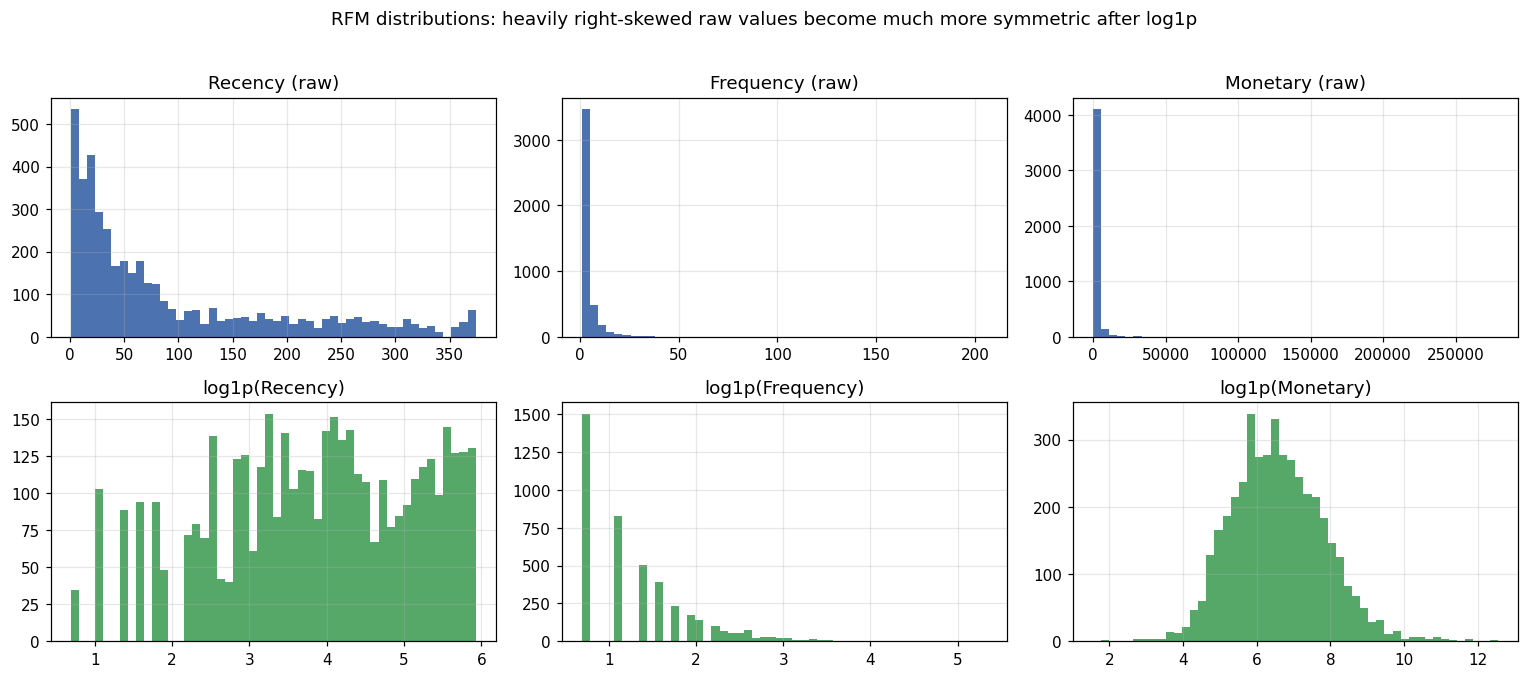

Skewness raw  : {'Recency': 1.24, 'Frequency': 11.95, 'Monetary': 19.58}
Skewness log1p: {'Recency': -0.33, 'Frequency': 1.21, 'Monetary': 0.4}

Correlation of log-RFM features:


,Recency,Frequency,Monetary
Recency,1.00,-0.57,-0.49
Frequency,-0.57,1.00,0.81
Monetary,-0.49,0.81,1.00


In [6]:
rfm_log = np.log1p(rfm)

fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for j, f in enumerate(FEATURES):
    axes[0, j].hist(rfm[f], bins=50, color="#4C72B0"); axes[0, j].set_title(f"{f} (raw)")
    axes[1, j].hist(rfm_log[f], bins=50, color="#55A868"); axes[1, j].set_title(f"log1p({f})")
plt.suptitle("RFM distributions: heavily right-skewed raw values become much more symmetric after log1p", y=1.02)
plt.tight_layout(); plt.show()

print("Skewness raw  :", rfm.skew().round(2).to_dict())
print("Skewness log1p:", rfm_log.skew().round(2).to_dict())
print("\nCorrelation of log-RFM features:")
display(rfm_log.corr().round(2))

**Why log + standardise?**
Frequency and Monetary are extremely right-skewed (a few "whale" customers spend 100x the median). Both K-Means and DBSCAN use Euclidean distance, so without a transform the clusters would be decided almost only by the whales, and without scaling the feature with the largest numbers (Monetary) would dominate the distance. `log1p` compresses the tail and `StandardScaler` puts all three features on the same scale (mean 0, std 1).

In [7]:
scaler = StandardScaler()
X = scaler.fit_transform(rfm_log[FEATURES])
X_df = pd.DataFrame(X, index=rfm.index, columns=FEATURES)
print("Scaled feature means:", X.mean(axis=0).round(3), "| stds:", X.std(axis=0).round(3))

Scaled feature means: [-0. -0.  0.] | stds: [1. 1. 1.]


## 6. PCA - dimensionality reduction
With only 3 RFM features PCA is a small step, but it answers two useful questions: *how much information survives in 2-D?* (needed for plotting) and *which feature combinations drive the variance?* (the loadings).

Explained variance ratio: [0.751 0.187 0.061] | cumulative: [0.751 0.939 1.   ]

Loadings (how each original feature contributes to each component):


,PC1,PC2,PC3
Recency,-0.513,0.849,0.126
Frequency,0.618,0.262,0.741
Monetary,0.597,0.458,-0.659


2 components keep 93.9% of the variance


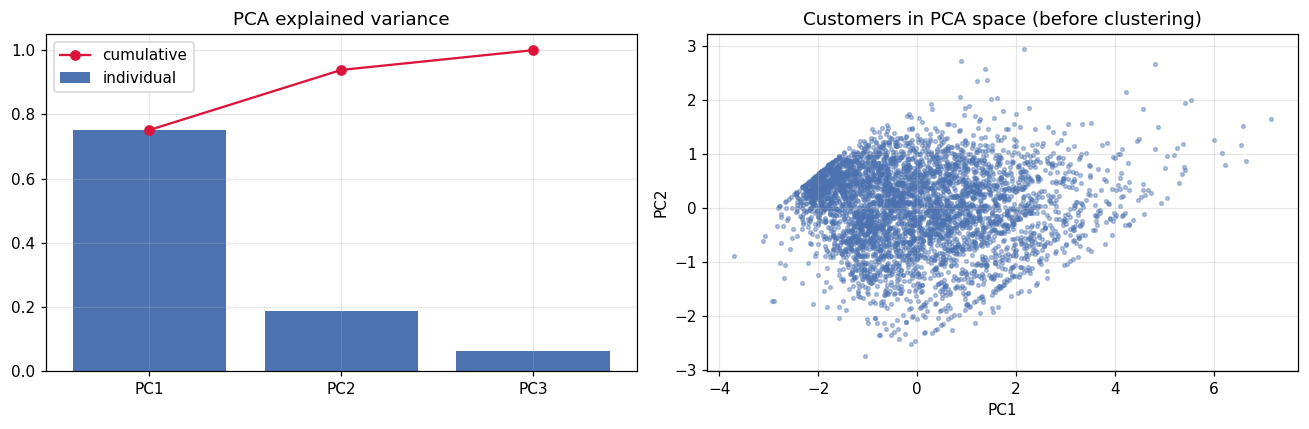

In [8]:
pca_full = PCA(n_components=3, random_state=SEED).fit(X)
evr = pca_full.explained_variance_ratio_
loadings = pd.DataFrame(pca_full.components_.T, index=FEATURES, columns=["PC1", "PC2", "PC3"]).round(3)

print("Explained variance ratio:", evr.round(3), "| cumulative:", evr.cumsum().round(3))
print("\nLoadings (how each original feature contributes to each component):")
display(loadings)

pca2 = PCA(n_components=2, random_state=SEED)
X_pca = pca2.fit_transform(X)
print(f"2 components keep {pca2.explained_variance_ratio_.sum() * 100:.1f}% of the variance")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(["PC1", "PC2", "PC3"], evr, color="#4C72B0", label="individual")
ax[0].plot(["PC1", "PC2", "PC3"], evr.cumsum(), "o-", color="crimson", label="cumulative")
ax[0].set_ylim(0, 1.05); ax[0].set_title("PCA explained variance"); ax[0].legend()
ax[1].scatter(X_pca[:, 0], X_pca[:, 1], s=6, alpha=0.4, color="#4C72B0")
ax[1].set_xlabel("PC1"); ax[1].set_ylabel("PC2"); ax[1].set_title("Customers in PCA space (before clustering)")
plt.tight_layout(); plt.show()

# Part A - K-Means
## 7. Choosing k
No single metric is perfect, so we look at four together:
- **Inertia / elbow** (lower is better, look for the bend),
- **Silhouette** (higher is better, range -1..1),
- **Davies-Bouldin** (lower is better),
- **Calinski-Harabasz** (higher is better).

`k` is picked automatically as the best-silhouette value inside `K_RANGE_FOR_CHOICE` (k=2 would give only "good" vs "bad" customers - too coarse for marketing personas). You can override it with `K_FORCE`.

,k,inertia,silhouette,davies_bouldin,calinski_harabasz
0,2,6469.806,0.433,0.890,4373.793
1,3,4850.075,0.338,1.041,3639.783
2,4,3918.819,0.336,1.018,3345.445
3,5,3262.383,0.318,0.983,3230.993
4,6,2835.922,0.313,1.014,3102.977
5,7,2528.029,0.304,0.989,2987.924
6,8,2326.662,0.297,1.015,2835.596
7,9,2146.571,0.281,1.021,2733.999
8,10,1987.681,0.277,1.028,2662.299



Best silhouette inside k=3..8: k = 3  ->  using K = 3


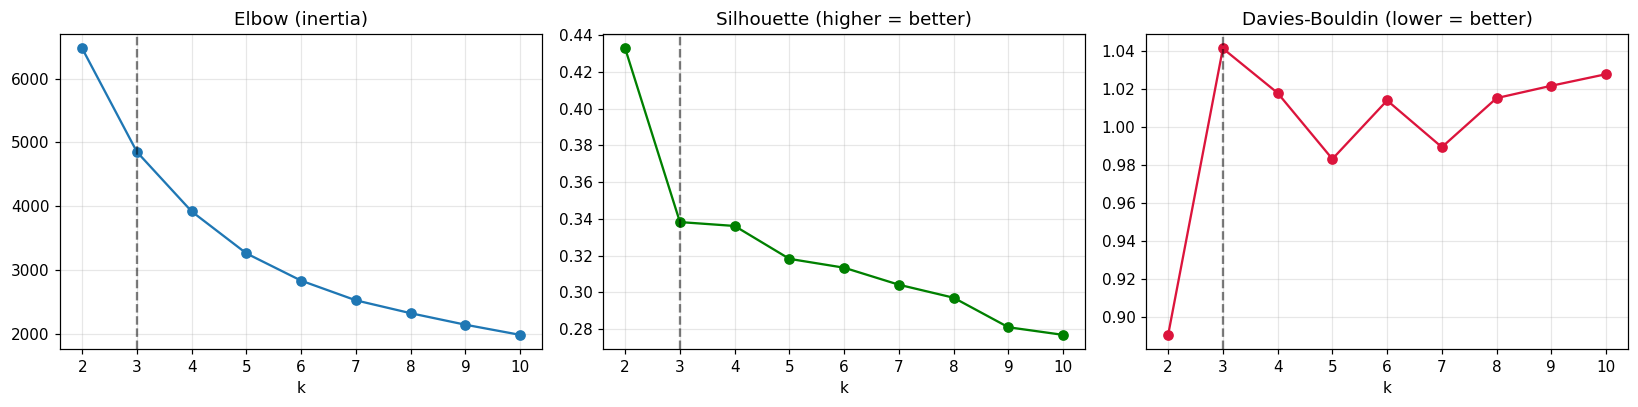

In [9]:
rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(X)
    rows.append({"k": k, "inertia": km.inertia_,
                 "silhouette": silhouette_score(X, km.labels_),
                 "davies_bouldin": davies_bouldin_score(X, km.labels_),
                 "calinski_harabasz": calinski_harabasz_score(X, km.labels_)})
km_eval = pd.DataFrame(rows)
display(km_eval.round(3))

lo, hi = K_RANGE_FOR_CHOICE
cand = km_eval[(km_eval["k"] >= lo) & (km_eval["k"] <= hi)]
best_k = int(cand.sort_values("silhouette", ascending=False).iloc[0]["k"])
K = int(K_FORCE) if K_FORCE else best_k
print(f"\nBest silhouette inside k={lo}..{hi}: k = {best_k}  ->  using K = {K}")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(km_eval["k"], km_eval["inertia"], "o-"); ax[0].set_title("Elbow (inertia)")
ax[1].plot(km_eval["k"], km_eval["silhouette"], "o-", color="green"); ax[1].set_title("Silhouette (higher = better)")
ax[2].plot(km_eval["k"], km_eval["davies_bouldin"], "o-", color="crimson"); ax[2].set_title("Davies-Bouldin (lower = better)")
for a in ax:
    a.set_xlabel("k"); a.axvline(K, color="k", ls="--", alpha=0.5)
plt.tight_layout(); plt.show()

## 8. Final K-Means model
Clusters are renumbered so that **cluster 0 = highest average spend**, 1 = next, and so on (K-Means numbering is otherwise arbitrary), which keeps the report readable.

In [10]:
km_final = KMeans(n_clusters=K, n_init=50, random_state=SEED).fit(X)
tmp = pd.Series(km_final.labels_, index=rfm.index)
order = rfm.groupby(tmp)["Monetary"].mean().sort_values(ascending=False).index.tolist()
relabel = {old: new for new, old in enumerate(order)}
rfm["KMeans"] = tmp.map(relabel).astype(int)

print("Cluster sizes:"); print(rfm["KMeans"].value_counts().sort_index().to_string())
km_sil = silhouette_score(X, rfm["KMeans"])
km_db = davies_bouldin_score(X, rfm["KMeans"])
print(f"\nK-Means (K={K}) silhouette = {km_sil:.3f} | Davies-Bouldin = {km_db:.3f}")

# Robustness 1: is the result stable across random initialisations?
aris = [adjusted_rand_score(rfm["KMeans"], KMeans(n_clusters=K, n_init=1, random_state=s).fit_predict(X)) for s in range(10)]
print(f"Stability over 10 random inits (ARI vs final): mean {np.mean(aris):.3f}, min {np.min(aris):.3f}")

# Robustness 2: does clustering in 2-D PCA space give the same segments?
ari_pca = adjusted_rand_score(rfm["KMeans"], KMeans(n_clusters=K, n_init=20, random_state=SEED).fit_predict(X_pca))
print(f"ARI between clustering on full scaled RFM vs on the 2 PCA components: {ari_pca:.3f}")

Cluster sizes:
KMeans
0     755
1    1709
2    1870

K-Means (K=3) silhouette = 0.338 | Davies-Bouldin = 1.041
Stability over 10 random inits (ARI vs final): mean 0.980, min 0.940
ARI between clustering on full scaled RFM vs on the 2 PCA components: 0.962


# Part B - DBSCAN
DBSCAN does not need `k`; it needs **eps** (neighbourhood radius) and **min_samples**. Points that are not density-reachable are labelled **noise (-1)** - often unusual customers such as extreme spenders.

## 9. Choosing eps
1. **k-distance plot:** sort every point's distance to its `min_samples`-th neighbour; the "knee" suggests a good eps.
2. **Grid search:** try many eps values and keep the one with the best silhouette (computed on non-noise points) under sensible constraints - at least 2 clusters, noise <= 15%, and no single cluster swallowing more than 90% of the clustered points.

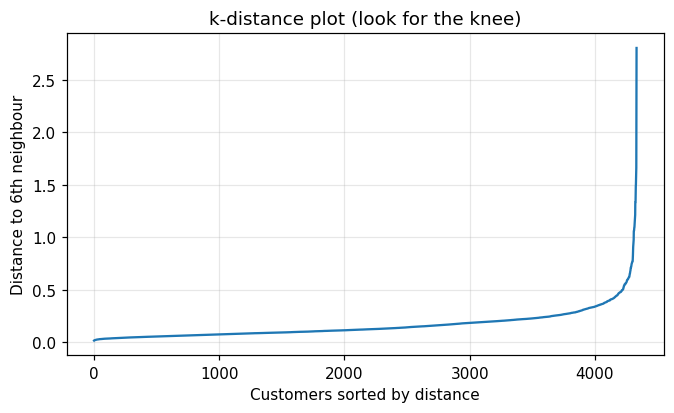

k-distance percentiles: {50: 0.122, 75: 0.204, 90: 0.306, 95: 0.397, 99: 0.717}


,eps,clusters,noise_%,largest_cluster_%,silhouette
0,0.100,55,50.1,52.9,-0.156
1,0.125,46,39.5,48.1,-0.131
2,0.150,33,31.8,45.6,-0.021
3,0.175,36,24.6,42.5,0.014
4,0.200,27,17.5,39.5,-0.066
5,0.225,17,12.9,37.8,0.028
6,0.250,8,10.2,36.8,0.060
7,0.275,9,8.0,35.9,0.073
8,0.300,5,6.6,36.2,0.108
9,0.325,4,5.3,35.8,0.134



Chosen eps = 0.45 (best silhouette among configurations meeting the constraints)


In [11]:
nn = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X)
kdist = np.sort(nn.kneighbors(X)[0][:, -1])

plt.figure(figsize=(7, 3.8))
plt.plot(kdist); plt.xlabel("Customers sorted by distance"); plt.ylabel(f"Distance to {MIN_SAMPLES}th neighbour")
plt.title("k-distance plot (look for the knee)"); plt.show()
print("k-distance percentiles:", {p: round(float(np.percentile(kdist, p)), 3) for p in (50, 75, 90, 95, 99)})

def run_dbscan(eps):
    lab = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(X)
    mask = lab != -1
    n_cl = len(set(lab[mask]))
    noise = 1 - mask.mean()
    share = (pd.Series(lab[mask]).value_counts(normalize=True).iloc[0]) if mask.any() else 1.0
    sil = silhouette_score(X[mask], lab[mask]) if n_cl >= 2 else np.nan
    return lab, {"eps": round(eps, 3), "clusters": n_cl, "noise_%": round(noise * 100, 1),
                 "largest_cluster_%": round(share * 100, 1), "silhouette": sil}

grid = []
for eps in np.arange(0.10, 0.80, 0.025):
    _, info = run_dbscan(eps)
    grid.append(info)
db_grid = pd.DataFrame(grid)
display(db_grid.round(3))

valid = db_grid[(db_grid["clusters"] >= 2) & (db_grid["noise_%"] <= 15) & (db_grid["largest_cluster_%"] <= 90)].dropna(subset=["silhouette"])
if len(valid):
    eps_best = float(valid.sort_values("silhouette", ascending=False).iloc[0]["eps"])
    print(f"\nChosen eps = {eps_best} (best silhouette among configurations meeting the constraints)")
else:
    relaxed = db_grid[(db_grid["clusters"] >= 2)].dropna(subset=["silhouette"])
    if len(relaxed):
        eps_best = float(relaxed.sort_values("silhouette", ascending=False).iloc[0]["eps"])
        print(f"\nNo configuration met all constraints; relaxed to best silhouette with >=2 clusters: eps = {eps_best}")
    else:
        eps_best = float(np.percentile(kdist, 95))
        print(f"\nNo grid value produced >=2 clusters; falling back to the 95th percentile k-distance: eps = {eps_best:.3f}")

In [12]:
db_labels, db_info = run_dbscan(eps_best)
rfm["DBSCAN"] = db_labels
n_clusters_db = len(set(db_labels) - {-1})
n_noise = int((db_labels == -1).sum())

print(f"DBSCAN(eps={eps_best}, min_samples={MIN_SAMPLES}) -> {n_clusters_db} clusters, "
      f"{n_noise} noise customers ({n_noise / len(rfm) * 100:.1f}%)")
print(rfm["DBSCAN"].value_counts().sort_index().to_string())

mask = db_labels != -1
if n_clusters_db >= 2:
    db_sil = silhouette_score(X[mask], db_labels[mask]); db_dbi = davies_bouldin_score(X[mask], db_labels[mask])
    print(f"Silhouette (non-noise points) = {db_sil:.3f} | Davies-Bouldin = {db_dbi:.3f}")
else:
    db_sil, db_dbi = np.nan, np.nan
    print("Only one cluster found - silhouette is undefined.")

print("\nMean RFM per DBSCAN group (noise = -1):")
display(rfm.groupby("DBSCAN")[FEATURES].agg(["mean", "count"]).round(1).iloc[:, [0, 2, 4, 5]])

DBSCAN(eps=0.45, min_samples=6) -> 2 clusters, 77 noise customers (1.8%)
DBSCAN
-1      77
 0    2764
 1    1493
Silhouette (non-noise points) = 0.297 | Davies-Bouldin = 1.063

Mean RFM per DBSCAN group (noise = -1):


Recency Frequency Monetary      
          mean      mean     mean count
DBSCAN                                 
-1        58.0      29.5  36650.8    77
 0        59.6       5.3   1948.6  2764
 1       157.3       1.0    354.4  1493

## 10. K-Means vs DBSCAN

In [13]:
cmp_ = pd.DataFrame([
    {"Method": f"K-Means (K={K})", "Clusters": K, "Noise points": 0,
     "Silhouette": round(km_sil, 3), "Davies-Bouldin": round(km_db, 3)},
    {"Method": f"DBSCAN (eps={eps_best})", "Clusters": n_clusters_db, "Noise points": n_noise,
     "Silhouette": round(db_sil, 3) if not np.isnan(db_sil) else np.nan,
     "Davies-Bouldin": round(db_dbi, 3) if not np.isnan(db_dbi) else np.nan},
]).set_index("Method")
display(cmp_)

print("Cross-tabulation (rows = K-Means cluster, columns = DBSCAN label, -1 = noise):")
display(pd.crosstab(rfm["KMeans"], rfm["DBSCAN"]))
ari_cmp = adjusted_rand_score(rfm["KMeans"], rfm["DBSCAN"])
print(f"Adjusted Rand Index between the two partitions: {ari_cmp:.3f}  (1 = identical, ~0 = unrelated)")

,Clusters,Noise points,Silhouette,Davies-Bouldin
Method,,,,
K-Means (K=3),3,0,0.338,1.041
DBSCAN (eps=0.45),2,77,0.297,1.063


Cross-tabulation (rows = K-Means cluster, columns = DBSCAN label, -1 = noise):


DBSCAN,-1,0,1
KMeans,,,
0,51,704,0
1,13,1556,140
2,13,504,1353


Adjusted Rand Index between the two partitions: 0.284  (1 = identical, ~0 = unrelated)


**How to read this comparison**
- **K-Means** forces *every* customer into one of K roughly spherical, similar-sized groups - ideal for building a fixed set of marketing segments, but it cannot say "this customer does not belong anywhere".
- **DBSCAN** finds density-based groups of any shape and flags **outliers as noise**. Customer RFM data forms one continuous "cloud" with no natural gaps, so DBSCAN can only cut it into a few broad density regions (here typically 2) and labels the sparse extremes as noise - useful for **spotting extreme/VIP/anomalous customers**, but it cannot give the finer, business-friendly segmentation that K-Means gives. Check the noise group's share of revenue in the table below: a tiny group of customers can carry a large part of the money.
- Practical conclusion: use **K-Means for the persona segmentation** and **DBSCAN as a complementary outlier detector**.

## 11. t-SNE visualisation
t-SNE embeds the 3-D scaled RFM space into 2-D while preserving *local neighbourhoods*. We colour the same embedding by K-Means, by DBSCAN and by log-spend. Two cautions when reading it: distances **between** far-apart groups and cluster **sizes** in a t-SNE plot are not meaningful, and the picture depends on `perplexity` (we use 30; try 15-50).

t-SNE done. KL divergence: 0.741


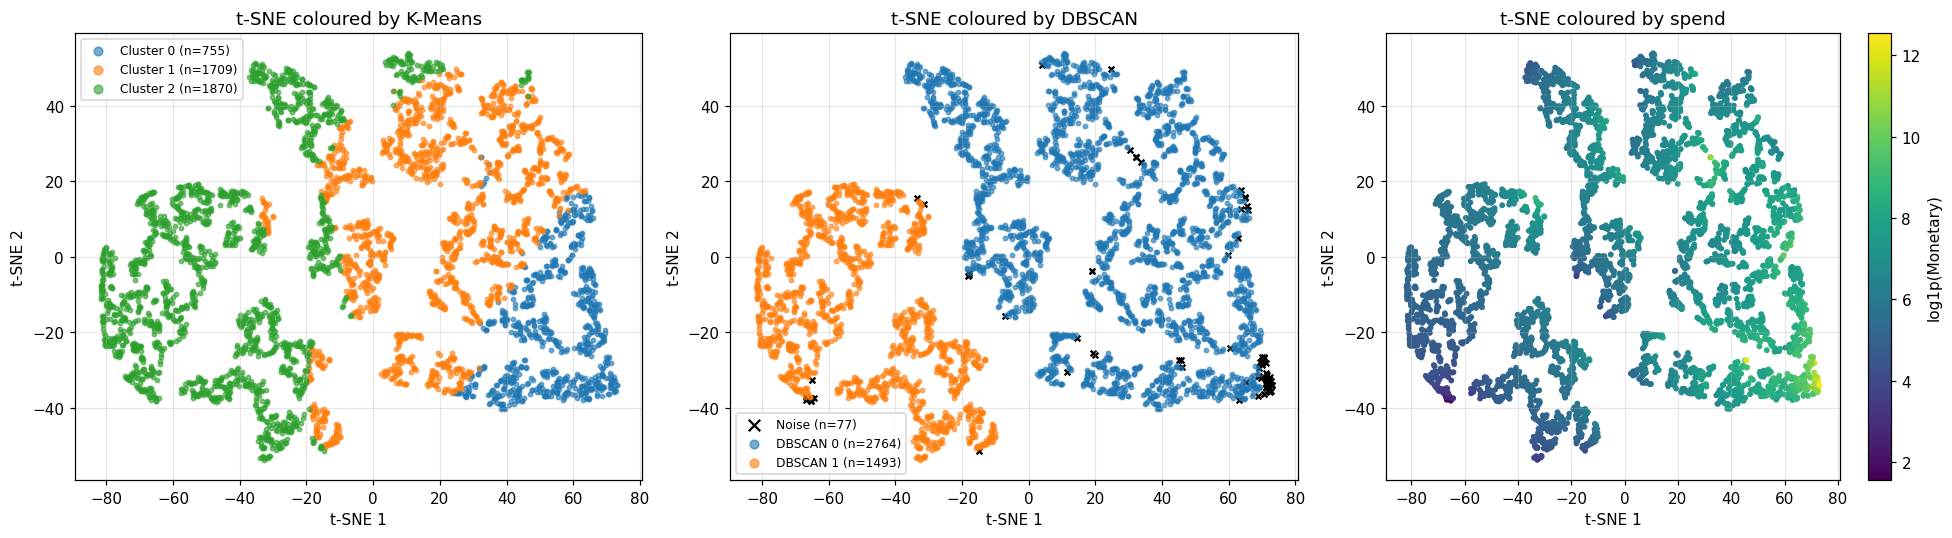

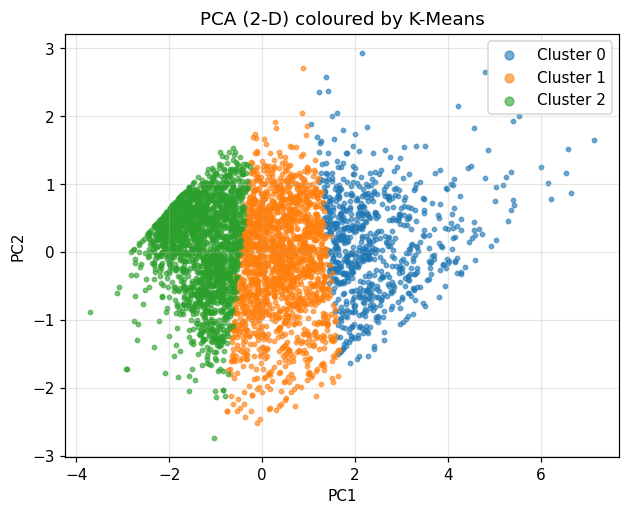

In [14]:
tsne = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=SEED)
X_tsne = tsne.fit_transform(X)
rfm["tsne1"], rfm["tsne2"] = X_tsne[:, 0], X_tsne[:, 1]
print("t-SNE done. KL divergence:", round(float(tsne.kl_divergence_), 3))

cmap = plt.get_cmap("tab10")
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

for c in range(K):
    m = (rfm["KMeans"] == c).values
    ax[0].scatter(X_tsne[m, 0], X_tsne[m, 1], s=8, alpha=0.6, color=cmap(c), label=f"Cluster {c} (n={m.sum()})")
ax[0].set_title("t-SNE coloured by K-Means"); ax[0].legend(markerscale=2, fontsize=8)

for lab in sorted(set(db_labels)):
    m = db_labels == lab
    if lab == -1:
        ax[1].scatter(X_tsne[m, 0], X_tsne[m, 1], s=14, color="black", marker="x", label=f"Noise (n={m.sum()})")
    else:
        ax[1].scatter(X_tsne[m, 0], X_tsne[m, 1], s=8, alpha=0.6, color=cmap(lab % 10), label=f"DBSCAN {lab} (n={m.sum()})")
ax[1].set_title("t-SNE coloured by DBSCAN"); ax[1].legend(markerscale=2, fontsize=8)

sc = ax[2].scatter(X_tsne[:, 0], X_tsne[:, 1], s=8, c=rfm_log["Monetary"], cmap="viridis")
plt.colorbar(sc, ax=ax[2], label="log1p(Monetary)"); ax[2].set_title("t-SNE coloured by spend")
for a in ax:
    a.set_xlabel("t-SNE 1"); a.set_ylabel("t-SNE 2")
plt.tight_layout(); plt.show()

# PCA view of the same K-Means result
plt.figure(figsize=(6.5, 5))
for c in range(K):
    m = (rfm["KMeans"] == c).values
    plt.scatter(X_pca[m, 0], X_pca[m, 1], s=8, alpha=0.6, color=cmap(c), label=f"Cluster {c}")
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("PCA (2-D) coloured by K-Means"); plt.legend(markerscale=2); plt.show()

# Part C - Personas and marketing actions
## 12. Profile every K-Means cluster
For each cluster we report its **size**, its average RFM in the original units, and its **share of customers vs. share of revenue** (the classic Pareto view).

,Customers,Recency_days_mean,Recency_days_median,Orders_mean,Orders_median,Spend_mean,Spend_median,Revenue_total,% customers,% revenue
KMeans,,,,,,,,,,
0,755,17.6,10.0,13.4,10.0,7881.0,3639.3,5950146.0,17.4,68.1
1,1709,44.3,30.0,3.4,3.0,1238.5,955.3,2116645.8,39.4,24.2
2,1870,168.5,160.0,1.3,1.0,358.5,292.2,670435.8,43.1,7.7


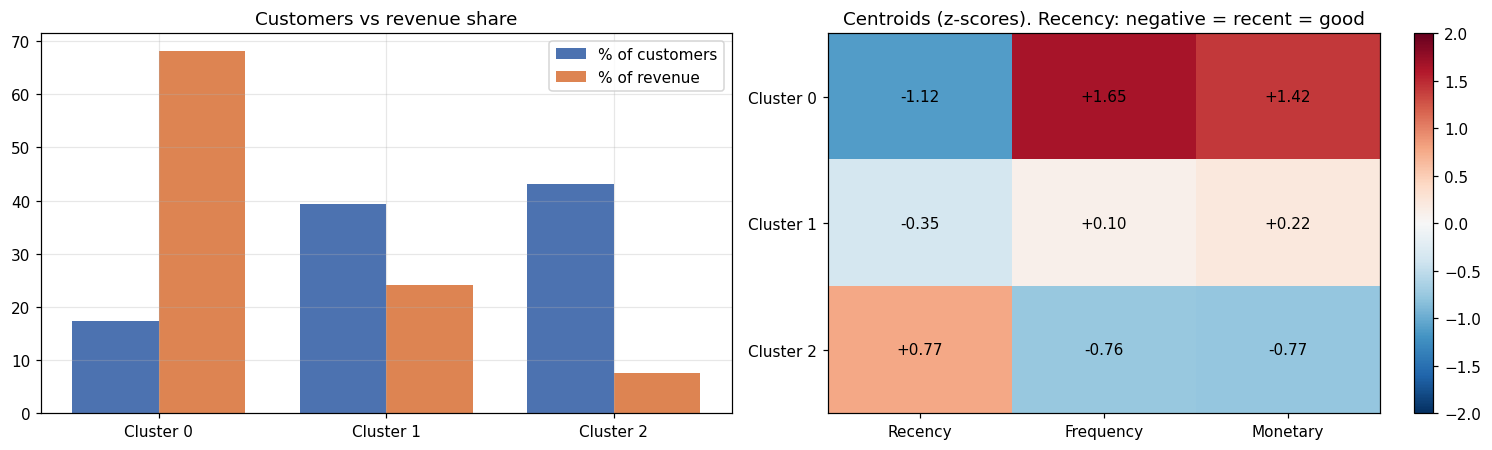

In [15]:
prof = rfm.groupby("KMeans").agg(
    Customers=("Monetary", "size"),
    Recency_days_mean=("Recency", "mean"), Recency_days_median=("Recency", "median"),
    Orders_mean=("Frequency", "mean"), Orders_median=("Frequency", "median"),
    Spend_mean=("Monetary", "mean"), Spend_median=("Monetary", "median"),
    Revenue_total=("Monetary", "sum"),
)
prof["% customers"] = prof["Customers"] / prof["Customers"].sum() * 100
prof["% revenue"] = prof["Revenue_total"] / prof["Revenue_total"].sum() * 100
display(prof.round(1))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
w = 0.38; idx = np.arange(K)
ax[0].bar(idx - w / 2, prof["% customers"], w, label="% of customers", color="#4C72B0")
ax[0].bar(idx + w / 2, prof["% revenue"], w, label="% of revenue", color="#DD8452")
ax[0].set_xticks(idx); ax[0].set_xticklabels([f"Cluster {i}" for i in idx]); ax[0].set_title("Customers vs revenue share"); ax[0].legend()

cz = X_df.groupby(rfm["KMeans"]).mean()                      # centroid in standardised log space
im = ax[1].imshow(cz.values, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
ax[1].set_xticks(range(3)); ax[1].set_xticklabels(FEATURES); ax[1].set_yticks(range(K)); ax[1].set_yticklabels([f"Cluster {i}" for i in range(K)])
for i in range(K):
    for j in range(3):
        ax[1].text(j, i, f"{cz.values[i, j]:+.2f}", ha="center", va="center", fontsize=10)
ax[1].set_title("Centroids (z-scores). Recency: negative = recent = good"); ax[1].grid(False); plt.colorbar(im, ax=ax[1])
plt.tight_layout(); plt.show()

## 13. Assign personas (rule-based, from the cluster centroids)
Rules use the centroid z-scores above (remember: **negative Recency = recent purchase = good**):

| Persona | Rule |
|---|---|
| **Champions** | recent AND high frequency AND high spend |
| **At-Risk Loyalists** | used to buy a lot (high F and M) but have not bought recently |
| **Hibernating / Lost** | long ago AND low frequency AND low spend |
| **Promising Recent Buyers** | bought recently but not yet high-value (we do not measure tenure, so they are not necessarily new customers) |
| **Casual Mid-Value** | everything else |

In [16]:
def name_persona(r, f, m):
    if r < 0 and f > 0.3 and m > 0.3:    return "Champions"
    if r >= 0 and f > 0 and m > 0:       return "At-Risk Loyalists"
    if r > 0.3 and f <= 0 and m <= 0:    return "Hibernating / Lost"
    if r < 0:                            return "Promising Recent Buyers"
    return "Casual Mid-Value"

ACTIONS = {
    "Champions": dict(
        goal="Retain, reward and turn into brand advocates.",
        tactics="VIP / early-access programme, free premium shipping, referral bonuses, ask for reviews and UGC, cross-sell premium bundles. Avoid blanket discounts (they already buy).",
        channels="Email + app push, personal account manager for the very top spenders.",
        kpis="Retention rate, referrals, average order value."),
    "At-Risk Loyalists": dict(
        goal="Win back before they churn - they are valuable but going quiet.",
        tactics="'We miss you' campaign with a personalised offer based on past purchases, reminder of loyalty points, limited-time back-in-stock alerts, short survey asking why they stopped.",
        channels="Email sequence (3 touches), retargeting ads, SMS for the highest value.",
        kpis="Reactivation rate, revenue recovered, days to next order."),
    "Hibernating / Lost": dict(
        goal="Low-cost reactivation only; do not over-invest.",
        tactics="Automated end-of-season clearance or big-discount win-back, then sunset the list if no response; exclude from paid campaigns to save budget.",
        channels="Cheap email only; suppress after 2-3 unanswered messages.",
        kpis="Reactivation rate vs. cost, list hygiene."),
    "Promising Recent Buyers": dict(
        goal="Grow into repeat, higher-value customers while they are still engaged.",
        tactics="Repeat-purchase incentive (e.g. discount on next order within 30 days), product recommendations ('customers also bought'), onboarding content, loyalty-programme invitation.",
        channels="Email + on-site recommendations.",
        kpis="Repeat-order rate, time between orders, frequency growth."),
    "Casual Mid-Value": dict(
        goal="Increase purchase frequency and basket size.",
        tactics="Free-shipping threshold slightly above their typical basket, bundle deals, seasonal campaigns and gift-guide emails, subscription / replenishment offers.",
        channels="Email newsletters, social ads, seasonal promotions.",
        kpis="Orders per year, average basket, revenue per customer."),
}

personas, used = {}, {}
for c in range(K):
    r, f, m = cz.loc[c, "Recency"], cz.loc[c, "Frequency"], cz.loc[c, "Monetary"]
    base = name_persona(r, f, m)
    used[base] = used.get(base, 0) + 1
    personas[c] = base if used[base] == 1 else f"{base} #{used[base]}"
rfm["Persona"] = rfm["KMeans"].map(personas)

cards = prof[["Customers", "% customers", "% revenue", "Recency_days_median", "Orders_median", "Spend_median"]].copy()
cards.insert(0, "Persona", [personas[c] for c in cards.index])
cards = cards.rename(columns={"Recency_days_median": "Median recency (days)", "Orders_median": "Median orders", "Spend_median": "Median spend"})
display(cards.round(1))

,Persona,Customers,% customers,% revenue,Median recency (days),Median orders,Median spend
KMeans,,,,,,,
0,Champions,755,17.4,68.1,10.0,10.0,3639.3
1,Promising Recent Buyers,1709,39.4,24.2,30.0,3.0,955.3
2,Hibernating / Lost,1870,43.1,7.7,160.0,1.0,292.2


In [17]:
for c in range(K):
    base = personas[c].split(" #")[0]
    a = ACTIONS[base]
    row = prof.loc[c]
    print("=" * 100)
    print(f"CLUSTER {c}: {personas[c].upper()}   |   {int(row['Customers'])} customers ({row['% customers']:.1f}%), {row['% revenue']:.1f}% of revenue")
    print(f"  Typical customer: last bought ~{row['Recency_days_median']:.0f} days ago, {row['Orders_median']:.0f} order(s), spend ~{row['Spend_median']:,.0f}")
    print(f"  Goal    : {a['goal']}")
    print(f"  Tactics : {a['tactics']}")
    print(f"  Channels: {a['channels']}")
    print(f"  KPIs    : {a['kpis']}")
print("=" * 100)

CLUSTER 0: CHAMPIONS   |   755 customers (17.4%), 68.1% of revenue
  Typical customer: last bought ~10 days ago, 10 order(s), spend ~3,639
  Goal    : Retain, reward and turn into brand advocates.
  Tactics : VIP / early-access programme, free premium shipping, referral bonuses, ask for reviews and UGC, cross-sell premium bundles. Avoid blanket discounts (they already buy).
  Channels: Email + app push, personal account manager for the very top spenders.
  KPIs    : Retention rate, referrals, average order value.
CLUSTER 1: PROMISING RECENT BUYERS   |   1709 customers (39.4%), 24.2% of revenue
  Typical customer: last bought ~30 days ago, 3 order(s), spend ~955
  Goal    : Grow into repeat, higher-value customers while they are still engaged.
  Tactics : Repeat-purchase incentive (e.g. discount on next order within 30 days), product recommendations ('customers also bought'), onboarding content, loyalty-programme invitation.
  Channels: Email + on-site recommendations.
  KPIs    : Repea

## 14. Using DBSCAN's noise points: the "VIP / anomaly" list
Customers that DBSCAN could not place in any dense region are statistically unusual. Looking at them separately is valuable for **account management** (extreme spenders) and **fraud / data-quality checks** (very odd order patterns).

In [18]:
noise_df = rfm[rfm["DBSCAN"] == -1]
core_df = rfm[rfm["DBSCAN"] != -1]
print(f"{len(noise_df)} noise customers = {len(noise_df) / len(rfm) * 100:.1f}% of customers, "
      f"{noise_df['Monetary'].sum() / rfm['Monetary'].sum() * 100:.1f}% of revenue")
display(pd.DataFrame({"Noise (median)": noise_df[FEATURES].median(), "Core (median)": core_df[FEATURES].median()}).round(1))
print("\nTop 10 noise customers by spend:")
display(noise_df.sort_values("Monetary", ascending=False)[FEATURES + ["KMeans", "Persona"]].head(10).round(1))
print("K-Means persona distribution among noise points:")
print(noise_df["Persona"].value_counts().to_string())

77 noise customers = 1.8% of customers, 32.3% of revenue


,Noise (median),Core (median)
Recency,10.0,52.0
Frequency,15.0,2.0
Monetary,16587.1,653.8



Top 10 noise customers by spend:


,Recency,Frequency,Monetary,KMeans,Persona
CustomerID,,,,,
14646,2,72,279138.0,0,Champions
18102,1,60,259657.3,0,Champions
17450,9,46,194390.8,0,Champions
16446,1,2,168472.5,0,Champions
14911,2,198,136161.8,0,Champions
12415,25,20,124564.5,0,Champions
14156,10,54,116560.1,0,Champions
17511,3,31,91062.4,0,Champions
12346,326,1,77183.6,1,Promising Recent Buyers


K-Means persona distribution among noise points:
Persona
Champions                  51
Promising Recent Buyers    13
Hibernating / Lost         13


## 15. Export the segmented customers

In [19]:
out = rfm[FEATURES + ["KMeans", "Persona", "DBSCAN", "tsne1", "tsne2"]].reset_index()
out.to_csv("customer_segments_rfm.csv", index=False)
cards.round(2).to_csv("persona_summary.csv")
print("Saved: customer_segments_rfm.csv and persona_summary.csv")
try:
    from google.colab import files
    files.download("customer_segments_rfm.csv"); files.download("persona_summary.csv")
except Exception:
    pass   # not running in Colab - files are in the working directory
out.head()

Saved: customer_segments_rfm.csv and persona_summary.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

,CustomerID,Recency,Frequency,Monetary,KMeans,Persona,DBSCAN,tsne1,tsne2
0,12346,326,1,77183.60,1,Promising Recent Buyers,-1,32.133392,26.431126
1,12347,3,7,4310.00,0,Champions,0,42.772247,-30.406563
2,12348,76,4,1437.24,1,Promising Recent Buyers,0,41.445309,33.704758
3,12349,19,1,1457.55,1,Promising Recent Buyers,1,-13.235054,-27.148209
4,12350,311,1,294.40,2,Hibernating / Lost,1,-67.990623,11.370515
